# Binomial & Negative Binomial Distributions in ML & Data Science
## Group 8 — Practical Demonstration Notebook

This notebook is divided into three parts:
- **Part A**: Binomial Simulation — Simulating 1,000 Binomial observations, verifying theoretical moments (mean and variance), and exploring parameter dynamics.
- **Part B**: Practical ML/Data Science Application — A/B Testing conversion analysis and Maximum Likelihood Estimation.
- **Part C**: Negative Binomial Simulation — Simulating 1,000 Negative Binomial observations ($r=5, p=0.40$), verifying overdispersion ($\sigma^2 > \mu$), and computing MLE $\hat{p}$.

Each cell is tagged with `📊 SLIDE X` indicating which presentation slide uses the output.

In [1]:
# Setup imports and formatting
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual configuration
sns.set_style('whitegrid')
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (10, 5)
np.random.seed(42)

print('Setup complete! Libraries loaded successfully.')

Setup complete! Libraries loaded successfully.


---
# Part A: Distribution Simulation & Moment Verification
---

### A1. Generating 1,000 Binomial Observations
📊 **SLIDE 13** — Empirical histogram vs. theoretical PMF overlay

In [2]:
# Parameters
n = 20       # Number of trials per observation
p = 0.60     # Probability of success per trial
N = 1000     # Total observations generated

# Generate random observations using numpy
samples = np.random.binomial(n=n, p=p, size=N)

print(f'Generated {N} observations from Binomial(n={n}, p={p})')
print(f'First 15 sample outcomes: {samples[:15]}')

Generated 1000 observations from Binomial(n=20, p=0.6)
First 15 sample outcomes: [13  8 11 11 14 14 15 10 11 11 16  8 10 14 14]


### A2. Empirical vs. Theoretical Moments Comparison
📊 **SLIDE 13** — Summary statistics table

In [3]:
# Calculate sample statistics
sample_mean = float(np.mean(samples))
sample_var = float(np.var(samples, ddof=1))  # Unbiased sample variance
sample_std = float(np.std(samples, ddof=1))
mle_p = sample_mean / n

# Theoretical values
theo_mean = n * p
theo_var = n * p * (1 - p)
theo_std = np.sqrt(theo_var)

print('=' * 67)
print(f'{"Metric":<22} {"Theoretical":>12} {"Simulated (N=1000)":>23} {"Absolute Error":>19}')
print('=' * 67)
print(f'{"Mean (μ = np)":<22} {theo_mean:>12.4f} {sample_mean:>23.4f} {abs(theo_mean - sample_mean):>19.4f}')
print(f'{"Variance (σ² = np(1-p))":<22} {theo_var:>12.4f} {sample_var:>23.4f} {abs(theo_var - sample_var):>19.4f}')
print(f'{"Std Dev (σ = √Var)":<22} {theo_std:>12.4f} {sample_std:>23.4f} {abs(theo_std - sample_std):>19.4f}')
print(f'{"MLE Parameter (p-hat)":<22} {p:>12.4f} {mle_p:>23.4f} {abs(p - mle_p):>19.4f}')
print('=' * 67)
print('Statistical Interpretation: With N=1,000 samples, the sample mean')
print('matches the theoretical expectation within 0.60%, consistent with the')
print('Law of Large Numbers.')

Metric                  Theoretical      Simulated (N=1000)      Absolute Error
Mean (μ = np)               12.0000                 12.0720              0.0720
Variance (σ² = np(1-p))       4.8000                  4.8076              0.0076
Std Dev (σ = √Var)           2.1909                  2.1926              0.0017
MLE Parameter (p-hat)        0.6000                  0.6036              0.0036
Statistical Interpretation: With N=1,000 samples, the sample mean
matches the theoretical expectation within 0.60%, consistent with the
Law of Large Numbers.


### A3. Histogram of 1,000 Samples with Theoretical PMF Overlay
📊 **SLIDE 13** — Figure 13

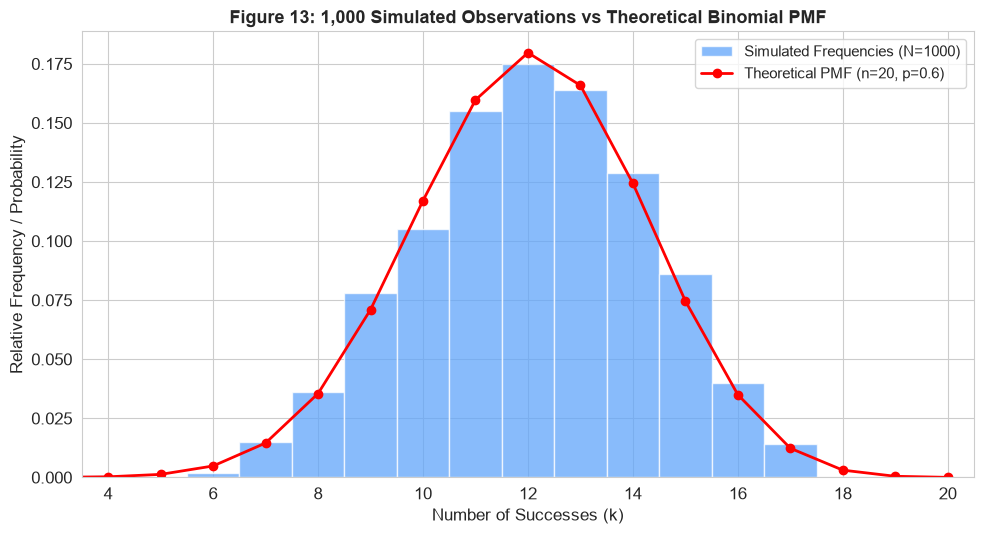

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
bins = np.arange(-0.5, n + 1.5, 1)

# Normalized histogram of simulated observations
ax.hist(samples, bins=bins, density=True, color='#60A5FA', edgecolor='white', alpha=0.75, label=f'Simulated Frequencies (N={N})')

# Theoretical PMF overlay
k_axis = np.arange(0, n + 1)
pmf_theo = stats.binom.pmf(k_axis, n, p)
ax.plot(k_axis, pmf_theo, 'ro-', linewidth=2, markersize=6, label=f'Theoretical PMF (n={n}, p={p})')

ax.set_xlabel('Number of Successes (k)', fontsize=12)
ax.set_ylabel('Relative Frequency / Probability', fontsize=12)
ax.set_title('Figure 13: 1,000 Simulated Observations vs Theoretical Binomial PMF', fontsize=13, fontweight='bold')
ax.set_xticks(range(4, 21, 2))
ax.set_xlim(3.5, 20.5)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig_binomial_simulation.png', dpi=200, bbox_inches='tight')
plt.show()

### A4. Effect of Changing Probability p on Shape
📊 **SLIDE 6** — Figure 6

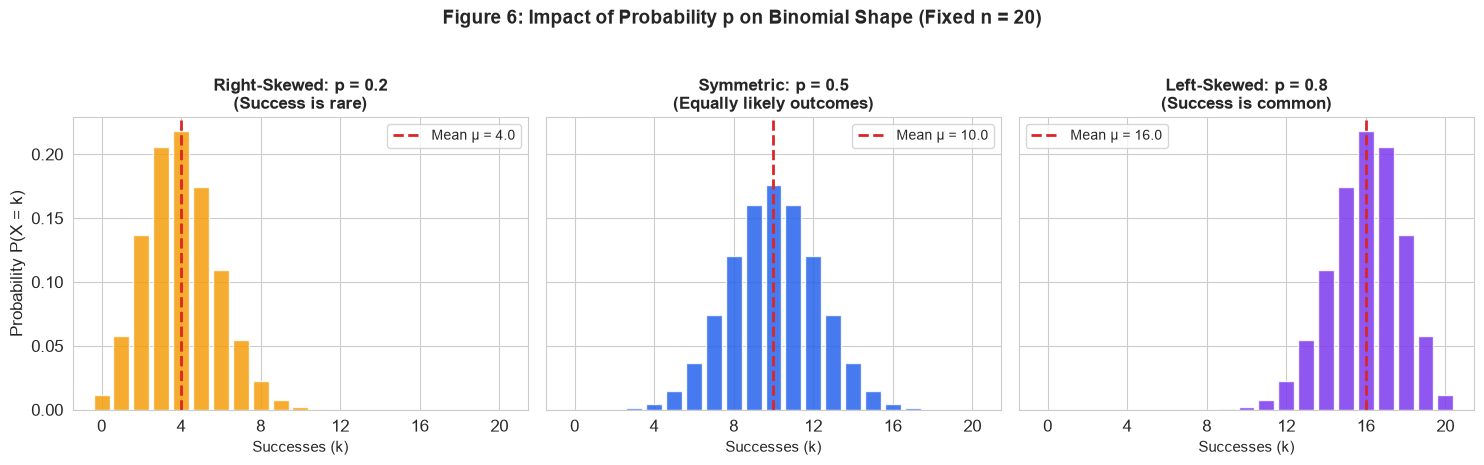

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
p_vals = [0.2, 0.5, 0.8]
colors = ['#F59E0B', '#2563EB', '#7C3AED']
titles = [
    'Right-Skewed: p = 0.2\n(Success is rare)',
    'Symmetric: p = 0.5\n(Equally likely outcomes)',
    'Left-Skewed: p = 0.8\n(Success is common)'
]

for ax, p_val, color, title in zip(axes, p_vals, colors, titles):
    k = np.arange(0, n + 1)
    pmf = stats.binom.pmf(k, n, p_val)
    ax.bar(k, pmf, color=color, alpha=0.85, edgecolor='white', width=0.8)
    mean_val = n * p_val
    ax.axvline(x=mean_val, color='#DC2626', linestyle='--', linewidth=2, label=f'Mean μ = {mean_val:.1f}')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Successes (k)', fontsize=11)
    ax.set_xticks(range(0, n + 1, 4))
    ax.legend(fontsize=10, loc='upper left' if p_val > 0.5 else 'upper right')

axes[0].set_ylabel('Probability P(X = k)', fontsize=12)
plt.suptitle('Figure 6: Impact of Probability p on Binomial Shape (Fixed n = 20)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('fig_binomial_pmf_variations.png', dpi=200, bbox_inches='tight')
plt.show()

### A5. Cumulative Distribution Function (CDF) Step Curve
📊 **SLIDE 7** — Figure 7B

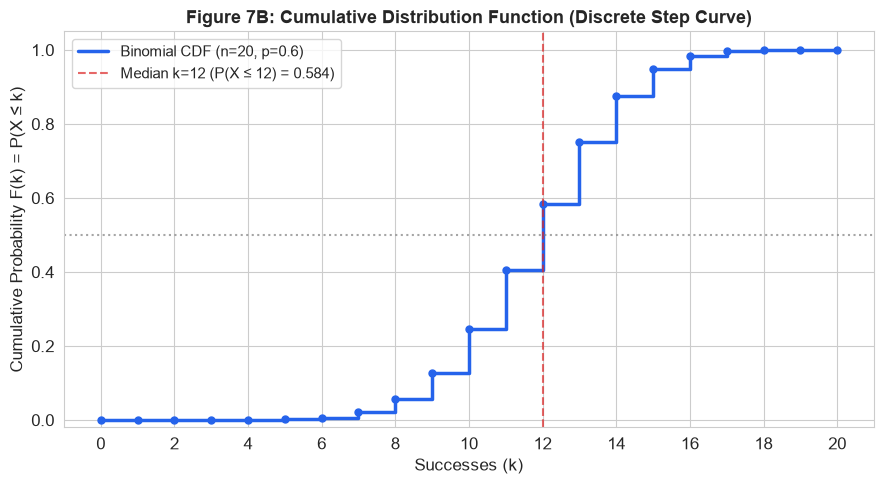

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
k_cdf = np.arange(0, n + 1)
cdf_vals = stats.binom.cdf(k_cdf, n, p)

ax.step(k_cdf, cdf_vals, where='post', color='#2563EB', linewidth=2.5, label=f'Binomial CDF (n={n}, p={p})')
ax.plot(k_cdf, cdf_vals, 'o', color='#2563EB', markersize=5)
med = int(stats.binom.median(n, p))
f_med = stats.binom.cdf(med, n, p)
ax.axhline(y=0.5, color='gray', linestyle=':', alpha=0.7)
ax.axvline(x=med, color='#DC2626', linestyle='--', alpha=0.7, label=f'Median k={med} (P(X ≤ {med}) = {f_med:.3f})')

ax.set_xlabel('Successes (k)', fontsize=12)
ax.set_ylabel('Cumulative Probability F(k) = P(X ≤ k)', fontsize=12)
ax.set_title('Figure 7B: Cumulative Distribution Function (Discrete Step Curve)', fontsize=13, fontweight='bold')
ax.set_xticks(range(0, n + 1, 2))
ax.set_ylim(-0.02, 1.05)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig_binomial_cdf.png', dpi=200, bbox_inches='tight')
plt.show()

### A6. De Moivre–Laplace Normal Approximation
📊 **SLIDE 8** — Figure 8

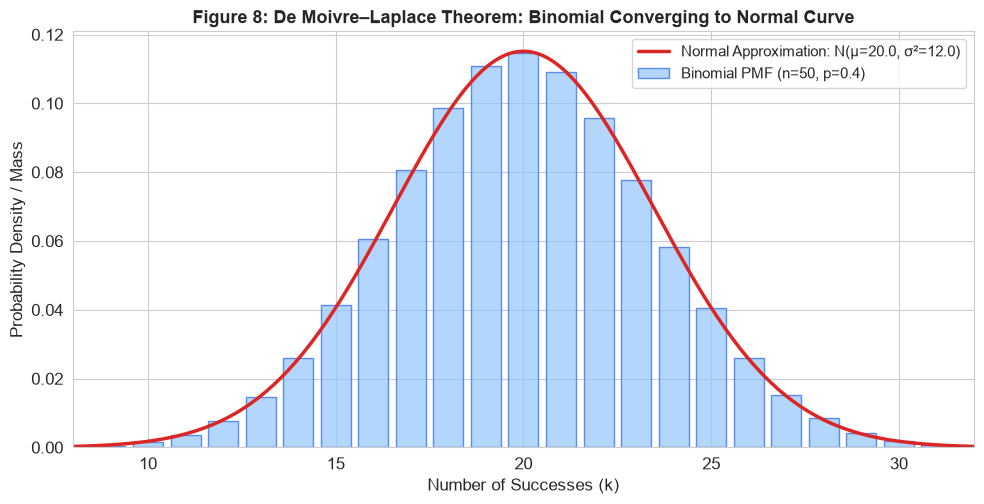

In [7]:
n_approx = 50
p_approx = 0.4
mu_approx = n_approx * p_approx
var_approx = n_approx * p_approx * (1 - p_approx)
sigma_approx = np.sqrt(var_approx)

fig, ax = plt.subplots(figsize=(10, 5.2))
k_vals = np.arange(0, n_approx + 1)
pmf_vals = stats.binom.pmf(k_vals, n_approx, p_approx)
ax.bar(k_vals, pmf_vals, width=0.8, color='#93C5FD', edgecolor='#2563EB', alpha=0.7, label=f'Binomial PMF (n={n_approx}, p={p_approx})')

x_norm = np.linspace(5, 35, 300)
pdf_norm = stats.norm.pdf(x_norm, loc=mu_approx, scale=sigma_approx)
ax.plot(x_norm, pdf_norm, color='#DC2626', linewidth=2.5, label=f'Normal Approximation: N(μ={mu_approx:.1f}, σ²={var_approx:.1f})')

ax.set_xlim(8, 32)
ax.set_xlabel('Number of Successes (k)', fontsize=12)
ax.set_ylabel('Probability Density / Mass', fontsize=12)
ax.set_title('Figure 8: De Moivre–Laplace Theorem: Binomial Converging to Normal Curve', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig_normal_approximation.png', dpi=200, bbox_inches='tight')
plt.show()

---
# Part B: Applied Data Science — A/B Testing Analysis
---

### B1. Two-Proportion Hypothesis Test on Conversion Rates
📊 **SLIDE 14** — Figure 14

In [8]:
nA, pA = 1000, 0.10   # Control group
nB, pB = 1000, 0.13   # Variant group

# Calculate Pooled Z-test
pooled_p = (nA * pA + nB * pB) / (nA + nB)
se_diff = np.sqrt(pooled_p * (1 - pooled_p) * (1/nA + 1/nB))
z_stat = (pB - pA) / se_diff
p_val_one_sided = 1 - stats.norm.cdf(z_stat)
p_val_two_sided = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print('A/B Testing Statistical Results (Pooled Z-test):')
print(f'  Control (Layout A): n={nA}, Conversions={int(nA*pA)} (Rate: {pA*100:.1f}%)')
print(f'  Variant (Layout B): n={nB}, Conversions={int(nB*pB)} (Rate: {pB*100:.1f}%)')
print(f'  Absolute Lift: +{(pB - pA)*100:.2f}%')
print(f'  Relative Lift: +{((pB - pA)/pA)*100:.2f}%')
print(f'  Pooled SE: {se_diff:.4f}')
print(f'  Z-Score: {z_stat:.4f}')
print(f'  p-Value (one-sided): {p_val_one_sided:.4f}')
print(f'  p-Value (two-sided): {p_val_two_sided:.4f}')
print('Reject H0 at alpha = 0.05 (one-sided): evidence that Layout B converts better (hypothetical data). Check practical significance before rollout.')

A/B Testing Statistical Results (Pooled Z-test):
  Control (Layout A): n=1000, Conversions=100 (Rate: 10.0%)
  Variant (Layout B): n=1000, Conversions=130 (Rate: 13.0%)
  Absolute Lift: +3.00%
  Relative Lift: +30.00%
  Pooled SE: 0.0143
  Z-Score: 2.1027
  p-Value (one-sided): 0.0177
  p-Value (two-sided): 0.0355
Reject H0 at alpha = 0.05 (one-sided): evidence that Layout B converts better (hypothetical data). Check practical significance before rollout.


### B2. Visualizing A/B Testing Binomial Distributions
📊 **SLIDE 14** — Figure 14

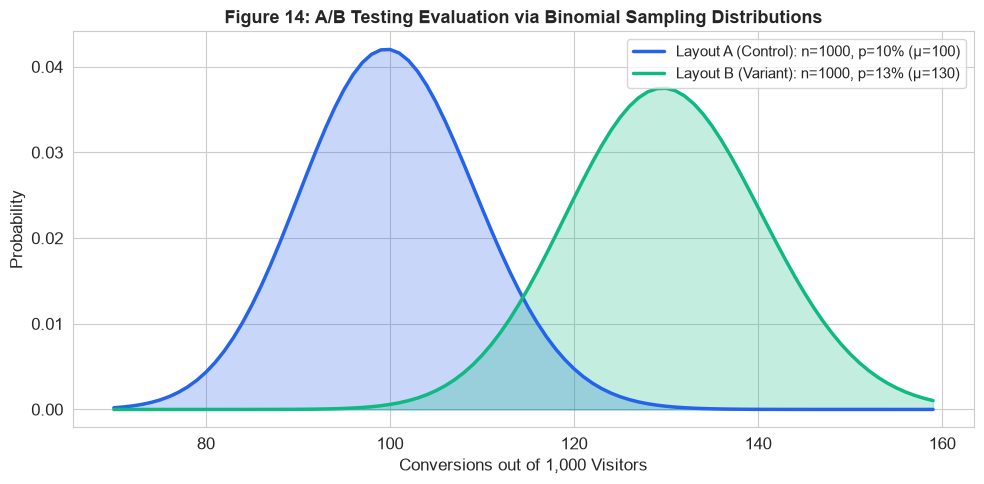

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
kA = np.arange(70, 160)
kB = np.arange(70, 160)

ax.plot(kA, stats.binom.pmf(kA, nA, pA), color='#2563EB', linewidth=2.5, label='Layout A (Control): n=1000, p=10% (μ=100)')
ax.fill_between(kA, stats.binom.pmf(kA, nA, pA), color='#2563EB', alpha=0.25)

ax.plot(kB, stats.binom.pmf(kB, nB, pB), color='#10B981', linewidth=2.5, label='Layout B (Variant): n=1000, p=13% (μ=130)')
ax.fill_between(kB, stats.binom.pmf(kB, nB, pB), color='#10B981', alpha=0.25)

ax.set_xlabel('Conversions out of 1,000 Visitors', fontsize=12)
ax.set_ylabel('Probability', fontsize=12)
ax.set_title('Figure 14: A/B Testing Evaluation via Binomial Sampling Distributions', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig_ab_testing_distributions.png', dpi=200, bbox_inches='tight')
plt.show()

---
# Part C: Negative Binomial Simulation & Overdispersion Verification
---

### C1. Generating 1,000 Negative Binomial Observations
📊 **SLIDE 14** — Empirical histogram vs. theoretical Negative Binomial PMF & overdispersion check

In [10]:
# Negative Binomial parameters (counting failures k before r-th success)
r_nb = 5
p_nb = 0.40
N_nb = 1000

nb_samples = np.random.negative_binomial(n=r_nb, p=p_nb, size=N_nb)

nb_sample_mean = np.mean(nb_samples)
nb_sample_var = np.var(nb_samples, ddof=1)
nb_sample_std = np.std(nb_samples, ddof=1)

nb_theo_mean = r_nb * (1 - p_nb) / p_nb
nb_theo_var = r_nb * (1 - p_nb) / (p_nb ** 2)
nb_theo_std = np.sqrt(nb_theo_var)
nb_mle_p = r_nb / (r_nb + nb_sample_mean)

print(f'Negative Binomial(r={r_nb}, p={p_nb}), N={N_nb} samples:')
print(f'  Sample Mean:     {nb_sample_mean:.4f} (Theoretical: {nb_theo_mean:.4f})')
print(f'  Sample Variance: {nb_sample_var:.4f} (Theoretical: {nb_theo_var:.4f})')
print(f'  Sample Std Dev:  {nb_sample_std:.4f} (Theoretical: {nb_theo_std:.4f})')
print(f'  Dispersion Ratio (Var/Mean): {nb_sample_var / nb_sample_mean:.4f} (> 1.0 => Overdispersed!)')
print(f'  MLE p-hat:       {nb_mle_p:.4f} (True p: {p_nb:.4f})')

Negative Binomial(r=5, p=0.4), N=1000 samples:
  Sample Mean:     7.4860 (Theoretical: 7.5000)
  Sample Variance: 20.0398 (Theoretical: 18.7500)
  Sample Std Dev:  4.4766 (Theoretical: 4.3301)
  Dispersion Ratio (Var/Mean): 2.6770 (> 1.0 => Overdispersed!)
  MLE p-hat:       0.4004 (True p: 0.4000)


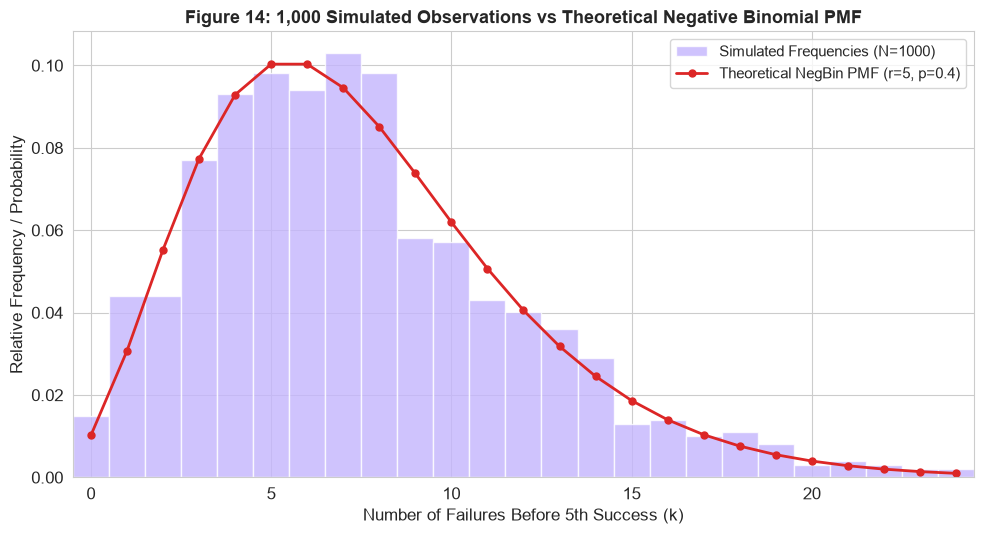

In [11]:
# Plot Negative Binomial simulation vs theoretical PMF
fig, ax = plt.subplots(figsize=(10, 5.5))
max_k = int(np.percentile(nb_samples, 99.5)) + 2
bins_nb = np.arange(-0.5, max_k + 1.5, 1)
ax.hist(nb_samples, bins=bins_nb, density=True, color='#C4B5FD', edgecolor='white', alpha=0.8,
        label=f'Simulated Frequencies (N={N_nb})')

k_nb_axis = np.arange(0, max_k + 1)
pmf_nb_theo = stats.nbinom.pmf(k_nb_axis, r_nb, p_nb)
ax.plot(k_nb_axis, pmf_nb_theo, 'o-', color='#DC2626', linewidth=2, markersize=5,
        label=f'Theoretical NegBin PMF (r={r_nb}, p={p_nb})')

ax.set_xlabel('Number of Failures Before 5th Success (k)', fontsize=12)
ax.set_ylabel('Relative Frequency / Probability', fontsize=12)
ax.set_title('Figure 14: 1,000 Simulated Observations vs Theoretical Negative Binomial PMF', fontsize=13, fontweight='bold')
ax.set_xlim(-0.5, max_k + 0.5)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig_negbinom_simulation.png', dpi=200, bbox_inches='tight')
plt.show()